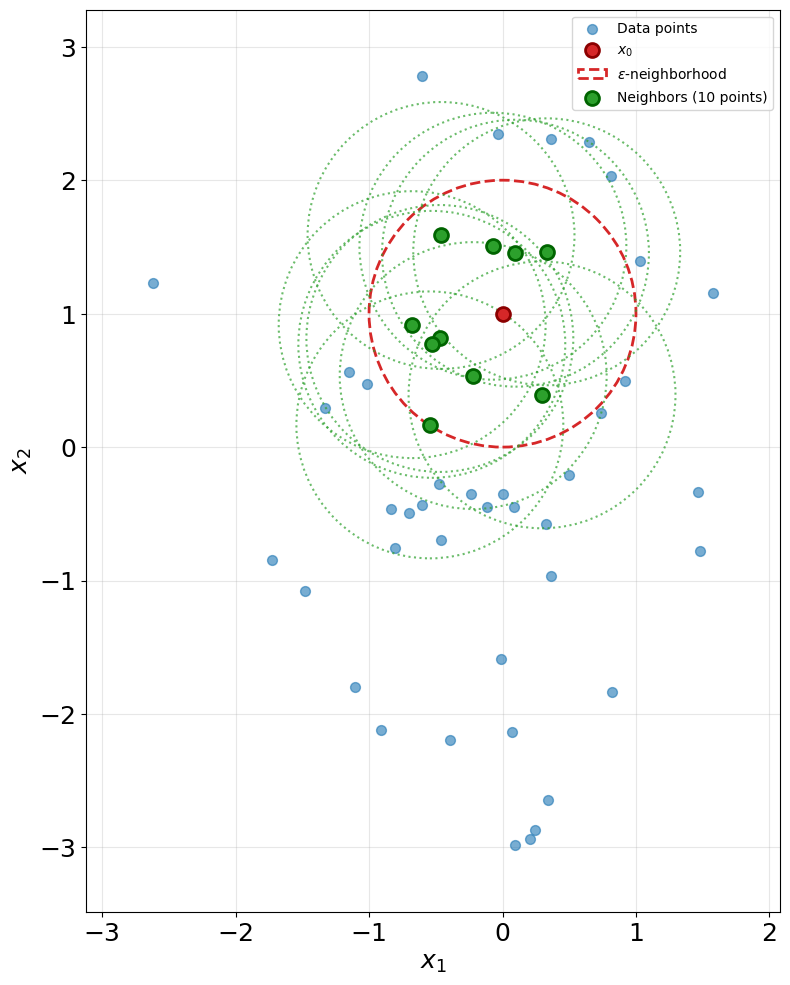

Total points: 50
Point x_0: (0.00, 1.00)


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# Set random seed for reproducibility
np.random.seed(42)

# Generate 50 points in 2D with vertical orientation (taller than wide)
# Using aspect ratio suitable for 3:2 height:width
n_points = 50
X = np.random.randn(n_points, 2)
X[:, 0] *= 1.0  # x-coordinate spread
X[:, 1] *= 1.5  # y-coordinate spread (larger for vertical orientation)

# Define the center point x_0 and radius epsilon
# x_0 = np.array([0.5, 0.5])
x_0 = np.array([0, 1])
# epsilon = 1.2
epsilon = 1

# Calculate distances from x_0 to all points
distances = np.sqrt(np.sum((X - x_0)**2, axis=1))

# Find neighbors (points within epsilon distance, excluding x_0 itself)
neighbors_mask = (distances < epsilon) & (distances > 0)
neighbors = X[neighbors_mask]

# Get tab10 colors
colors = plt.cm.tab10.colors
blue = colors[0]
red = colors[3]
green = colors[2]

# Create figure with 3:2 height:width ratio
fig, ax = plt.subplots(figsize=(8, 12))

# Plot all points in blue
ax.scatter(X[:, 0], X[:, 1], c=[blue], s=50, alpha=0.6, zorder=2, label='Data points')

# Plot x_0 in red
ax.scatter(x_0[0], x_0[1], c=[red], s=100, marker='o', zorder=4, 
           edgecolors='darkred', linewidths=2, label='$x_0$')

# Draw red circle around x_0
circle_x0 = Circle(x_0, epsilon, fill=False, edgecolor=red, linewidth=2, 
                    linestyle='--', zorder=3, label=f'$\epsilon$-neighborhood')
ax.add_patch(circle_x0)

# Plot neighbors in green and draw green circles around them
if len(neighbors) > 0:
    ax.scatter(neighbors[:, 0], neighbors[:, 1], c=[green], s=100, 
               marker='o', zorder=5, edgecolors='darkgreen', linewidths=2,
               label=f'Neighbors ({len(neighbors)} points)')
    
    for neighbor in neighbors:
        circle_neighbor = Circle(neighbor, epsilon, fill=False, 
                                edgecolor=green, linewidth=1.5, 
                                linestyle=':', zorder=3, alpha=0.7)
        ax.add_patch(circle_neighbor)

# Set equal aspect ratio and adjust limits
ax.set_aspect('equal')
margin = 0.5
ax.set_xlim(X[:, 0].min() - margin, X[:, 0].max() + margin)
ax.set_ylim(X[:, 1].min() - margin, X[:, 1].max() + margin)

# Labels and title
ax.set_xlabel('$x_1$', fontsize=18)
ax.set_ylabel('$x_2$', fontsize=18)
ax.tick_params(axis='both', which='major', labelsize=18)
# ax.tick_params(axis='both', which='minor', labelsize=18)
# ax.set_title(f'$\epsilon$-Neighborhood Visualization ($\epsilon = {epsilon}$)', 
#              fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("bblr_illustration.pdf")
plt.show()

# Print statistics
print(f"Total points: {n_points}")
# print(f"Number of neighbors within epsilon={epsilon}: {len(neighbors)}")
print(f"Point x_0: ({x_0[0]:.2f}, {x_0[1]:.2f})")

<>:48: SyntaxWarning: invalid escape sequence '\e'
<>:96: SyntaxWarning: invalid escape sequence '\e'
<>:102: SyntaxWarning: invalid escape sequence '\e'
<>:108: SyntaxWarning: invalid escape sequence '\e'
<>:48: SyntaxWarning: invalid escape sequence '\e'
<>:96: SyntaxWarning: invalid escape sequence '\e'
<>:102: SyntaxWarning: invalid escape sequence '\e'
<>:108: SyntaxWarning: invalid escape sequence '\e'
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2409015591.py:48: SyntaxWarning: invalid escape sequence '\e'
  label=f'Neighbors in $\epsilon$-neighborhood')
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2409015591.py:96: SyntaxWarning: invalid escape sequence '\e'
  alpha=0.7, label=f'$\epsilon$-boundaries')
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2409015591.py:102: SyntaxWarning: invalid escape sequence '\e'
  ax.text(x_0, interval_y + 0.05*(y_max - y_min), f'$2\epsilon = {2*epsilon:.1f}$',
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2409015

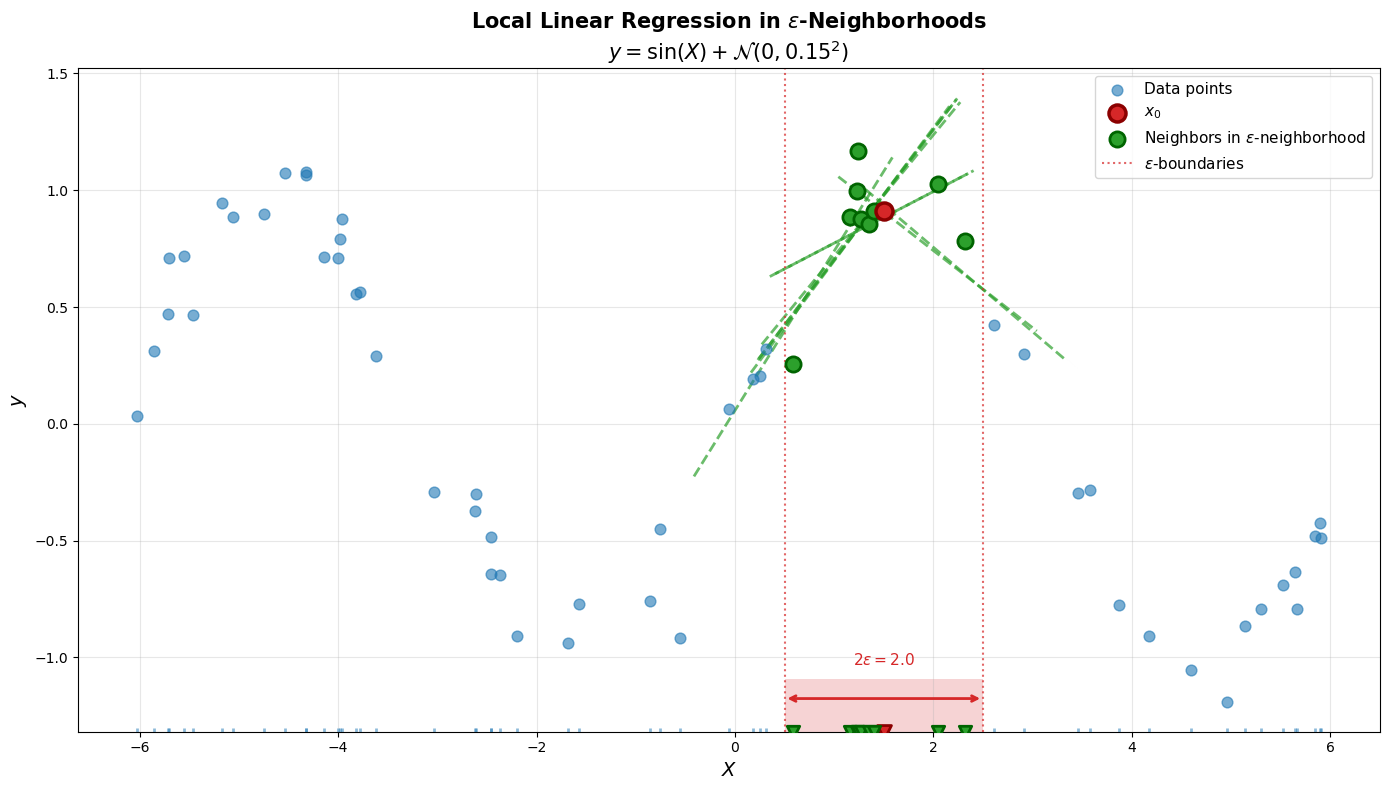

Total points: 60
Point x_0: 1.50
Epsilon: 1.00
Number of neighbors: 9

Neighbor points (x, y):
  (0.587, 0.256)
  (1.161, 0.884)
  (1.230, 0.996)
  (1.240, 1.167)
  (1.271, 0.878)
  (1.351, 0.855)
  (1.406, 0.911)
  (2.042, 1.028)
  (2.315, 0.785)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.linear_model import LinearRegression

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1D data points
n_points = 60
X = np.sort(np.random.uniform(-2*np.pi, 2*np.pi, n_points))
y = np.sin(X) + np.random.normal(0, 0.15, n_points)

# Define x_0 and epsilon
x_0 = 1.5
epsilon = 1.0

# Find neighbors within epsilon of x_0
neighbors_mask = (np.abs(X - x_0) < epsilon) & (X != x_0)
neighbors_X = X[neighbors_mask]
neighbors_y = y[neighbors_mask]

# Get tab10 colors
colors = plt.cm.tab10.colors
blue = colors[0]
red = colors[3]
green = colors[2]
orange = colors[1]

# Create figure
fig, ax = plt.subplots(figsize=(14, 8))

# Plot all points in blue
ax.scatter(X, y, c=[blue], s=60, alpha=0.6, zorder=3, label='Data points')

# Find x_0's position in data
x_0_idx = np.argmin(np.abs(X - x_0))
y_0 = y[x_0_idx]

# Plot x_0 in red
ax.scatter(x_0, y_0, c=[red], s=150, marker='o', zorder=5, 
           edgecolors='darkred', linewidths=2.5, label='$x_0$')

# Plot neighbors in green
if len(neighbors_X) > 0:
    ax.scatter(neighbors_X, neighbors_y, c=[green], s=120, 
               marker='o', zorder=4, edgecolors='darkgreen', linewidths=2,
               label=f'Neighbors in $\epsilon$-neighborhood')
    
    # For each neighbor, perform local linear regression and plot the line
    for i, (x_i, y_i) in enumerate(zip(neighbors_X, neighbors_y)):
        # Find points in epsilon neighborhood of x_i
        local_mask = np.abs(X - x_i) < epsilon
        X_local = X[local_mask].reshape(-1, 1)
        y_local = y[local_mask]
        
        # Perform linear regression
        if len(X_local) >= 2:  # Need at least 2 points
            lr = LinearRegression()
            lr.fit(X_local, y_local)
            
            # Generate line for plotting on interval [x_i - epsilon, x_i + epsilon]
            x_line = np.linspace(max(X.min(), x_i - epsilon), 
                                min(X.max(), x_i + epsilon), 100)
            y_line = lr.predict(x_line.reshape(-1, 1))
            
            # Plot regression line
            ax.plot(x_line, y_line, color=green, linewidth=2, 
                   alpha=0.7, zorder=2, linestyle='--')

# Draw epsilon interval on x-axis
y_min, y_max = ax.get_ylim()
interval_y = y_min + 0.05 * (y_max - y_min)

# Highlight epsilon neighborhood on x-axis
rect = Rectangle((x_0 - epsilon, y_min), 2*epsilon, 0.08*(y_max - y_min),
                 facecolor=red, alpha=0.2, zorder=1)
ax.add_patch(rect)

# Mark all points on x-axis
ax.scatter(X, np.full_like(X, y_min), c=[blue], s=40, alpha=0.5, 
           zorder=2, marker='|', linewidths=2)

# Mark x_0 on x-axis
ax.scatter(x_0, y_min, c=[red], s=100, marker='v', zorder=3,
           edgecolors='darkred', linewidths=2)

# Mark neighbors on x-axis
if len(neighbors_X) > 0:
    ax.scatter(neighbors_X, np.full_like(neighbors_X, y_min), 
               c=[green], s=80, marker='v', zorder=3,
               edgecolors='darkgreen', linewidths=2)

# Draw vertical lines to show epsilon boundaries
ax.axvline(x_0 - epsilon, color=red, linestyle=':', linewidth=1.5, 
           alpha=0.7, label=f'$\epsilon$-boundaries')
ax.axvline(x_0 + epsilon, color=red, linestyle=':', linewidth=1.5, alpha=0.7)

# Add epsilon interval annotation
ax.annotate('', xy=(x_0 + epsilon, interval_y), xytext=(x_0 - epsilon, interval_y),
            arrowprops=dict(arrowstyle='<->', color=red, lw=2))
ax.text(x_0, interval_y + 0.05*(y_max - y_min), f'$2\epsilon = {2*epsilon:.1f}$', 
        ha='center', fontsize=11, color=red, fontweight='bold')

# Labels and title
ax.set_xlabel('$X$', fontsize=14)
ax.set_ylabel('$y$', fontsize=14)
ax.set_title('Local Linear Regression in $\epsilon$-Neighborhoods\n' + 
             r'$y = \sin(X) + \mathcal{N}(0, 0.15^2)$', 
             fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

# Print statistics
print(f"Total points: {n_points}")
print(f"Point x_0: {x_0:.2f}")
print(f"Epsilon: {epsilon:.2f}")
print(f"Number of neighbors: {len(neighbors_X)}")
print(f"\nNeighbor points (x, y):")
for x_i, y_i in zip(neighbors_X, neighbors_y):
    print(f"  ({x_i:.3f}, {y_i:.3f})")

<>:48: SyntaxWarning: invalid escape sequence '\e'
<>:105: SyntaxWarning: invalid escape sequence '\e'
<>:111: SyntaxWarning: invalid escape sequence '\e'
<>:117: SyntaxWarning: invalid escape sequence '\e'
<>:48: SyntaxWarning: invalid escape sequence '\e'
<>:105: SyntaxWarning: invalid escape sequence '\e'
<>:111: SyntaxWarning: invalid escape sequence '\e'
<>:117: SyntaxWarning: invalid escape sequence '\e'
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2174736052.py:48: SyntaxWarning: invalid escape sequence '\e'
  label=f'Neighbors in $\epsilon$-neighborhood')
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2174736052.py:105: SyntaxWarning: invalid escape sequence '\e'
  alpha=0.7, label=f'$\epsilon$-boundaries')
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2174736052.py:111: SyntaxWarning: invalid escape sequence '\e'
  ax.text(x_0, interval_y + 0.05*(y_max - y_min), f'$2\epsilon = {2*epsilon:.1f}$',
C:\Users\sylwester\AppData\Local\Temp\ipykernel_65144\2174

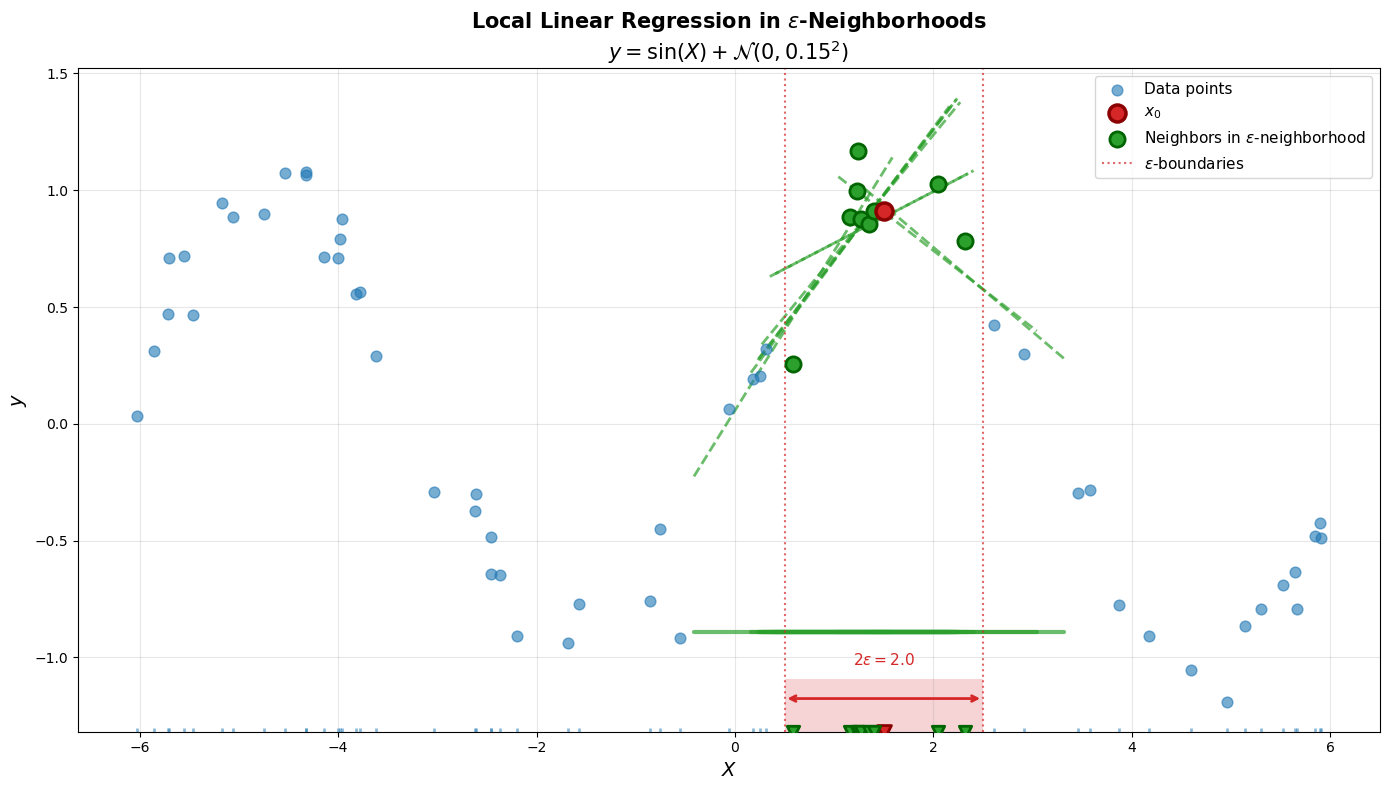

Total points: 60
Point x_0: 1.50
Epsilon: 1.00
Number of neighbors: 9

Neighbor points (x, y):
  (0.587, 0.256)
  (1.161, 0.884)
  (1.230, 0.996)
  (1.240, 1.167)
  (1.271, 0.878)
  (1.351, 0.855)
  (1.406, 0.911)
  (2.042, 1.028)
  (2.315, 0.785)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from sklearn.linear_model import LinearRegression

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1D data points
n_points = 60
X = np.sort(np.random.uniform(-2*np.pi, 2*np.pi, n_points))
y = np.sin(X) + np.random.normal(0, 0.15, n_points)

# Define x_0 and epsilon
x_0 = 1.5
epsilon = 1.0

# Find neighbors within epsilon of x_0
neighbors_mask = (np.abs(X - x_0) < epsilon) & (X != x_0)
neighbors_X = X[neighbors_mask]
neighbors_y = y[neighbors_mask]

# Get tab10 colors
colors = plt.cm.tab10.colors
blue = colors[0]
red = colors[3]
green = colors[2]
orange = colors[1]

# Create figure
fig, ax = plt.subplots(figsize=(14, 8))

# Plot all points in blue
ax.scatter(X, y, c=[blue], s=60, alpha=0.6, zorder=3, label='Data points')

# Find x_0's position in data
x_0_idx = np.argmin(np.abs(X - x_0))
y_0 = y[x_0_idx]

# Plot x_0 in red
ax.scatter(x_0, y_0, c=[red], s=150, marker='o', zorder=5, 
           edgecolors='darkred', linewidths=2.5, label='$x_0$')

# Plot neighbors in green
if len(neighbors_X) > 0:
    ax.scatter(neighbors_X, neighbors_y, c=[green], s=120, 
               marker='o', zorder=4, edgecolors='darkgreen', linewidths=2,
               label=f'Neighbors in $\epsilon$-neighborhood')
    
    # For each neighbor, perform local linear regression and plot the line
    for i, (x_i, y_i) in enumerate(zip(neighbors_X, neighbors_y)):
        # Find points in epsilon neighborhood of x_i
        local_mask = np.abs(X - x_i) < epsilon
        X_local = X[local_mask].reshape(-1, 1)
        y_local = y[local_mask]
        
        # Perform linear regression
        if len(X_local) >= 2:  # Need at least 2 points
            lr = LinearRegression()
            lr.fit(X_local, y_local)
            
            # Generate line for plotting on interval [x_i - epsilon, x_i + epsilon]
            x_line = np.linspace(max(X.min(), x_i - epsilon), 
                                min(X.max(), x_i + epsilon), 100)
            y_line = lr.predict(x_line.reshape(-1, 1))
            
            # Plot regression line
            ax.plot(x_line, y_line, color=green, linewidth=2, 
                   alpha=0.7, zorder=2, linestyle='--')

# Draw epsilon interval on x-axis
y_min, y_max = ax.get_ylim()
interval_y = y_min + 0.05 * (y_max - y_min)

# Highlight epsilon neighborhood on x-axis
rect = Rectangle((x_0 - epsilon, y_min), 2*epsilon, 0.08*(y_max - y_min),
                 facecolor=red, alpha=0.2, zorder=1)
ax.add_patch(rect)

# Mark all points on x-axis
ax.scatter(X, np.full_like(X, y_min), c=[blue], s=40, alpha=0.5, 
           zorder=2, marker='|', linewidths=2)

# Mark x_0 on x-axis
ax.scatter(x_0, y_min, c=[red], s=100, marker='v', zorder=3,
           edgecolors='darkred', linewidths=2)

# Mark neighbors on x-axis
if len(neighbors_X) > 0:
    ax.scatter(neighbors_X, np.full_like(neighbors_X, y_min), 
               c=[green], s=80, marker='v', zorder=3,
               edgecolors='darkgreen', linewidths=2)
    
    # Draw green lines for epsilon neighborhoods of each neighbor
    neighbor_line_y = y_min + 0.15 * (y_max - y_min)
    for x_i in neighbors_X:
        # Draw horizontal line showing [x_i - epsilon, x_i + epsilon]
        ax.plot([x_i - epsilon, x_i + epsilon], 
                [neighbor_line_y, neighbor_line_y],
                color=green, linewidth=3, alpha=0.7, zorder=2,
                solid_capstyle='round')

# Draw vertical lines to show epsilon boundaries
ax.axvline(x_0 - epsilon, color=red, linestyle=':', linewidth=1.5, 
           alpha=0.7, label=f'$\epsilon$-boundaries')
ax.axvline(x_0 + epsilon, color=red, linestyle=':', linewidth=1.5, alpha=0.7)

# Add epsilon interval annotation
ax.annotate('', xy=(x_0 + epsilon, interval_y), xytext=(x_0 - epsilon, interval_y),
            arrowprops=dict(arrowstyle='<->', color=red, lw=2))
ax.text(x_0, interval_y + 0.05*(y_max - y_min), f'$2\epsilon = {2*epsilon:.1f}$', 
        ha='center', fontsize=11, color=red, fontweight='bold')

# Labels and title
ax.set_xlabel('$X$', fontsize=14)
ax.set_ylabel('$y$', fontsize=14)
# ax.set_title('Local Linear Regression in $\epsilon$-Neighborhoods\n' + 
#              r'$y = \sin(X) + \mathcal{N}(0, 0.15^2)$', 
#              fontsize=15, fontweight='bold')
ax.set_title(r'$y = \sin(X) + \mathcal{N}(0, 0.15^2)$', 
             fontsize=15, fontweight='bold')
ax.legend(loc='upper right', fontsize=11)
ax.grid(True, alpha=0.3)
ax.set_ylim(y_min, y_max)

plt.tight_layout()
plt.show()

# Print statistics
print(f"Total points: {n_points}")
print(f"Point x_0: {x_0:.2f}")
print(f"Epsilon: {epsilon:.2f}")
print(f"Number of neighbors: {len(neighbors_X)}")
print(f"\nNeighbor points (x, y):")
for x_i, y_i in zip(neighbors_X, neighbors_y):
    print(f"  ({x_i:.3f}, {y_i:.3f})")